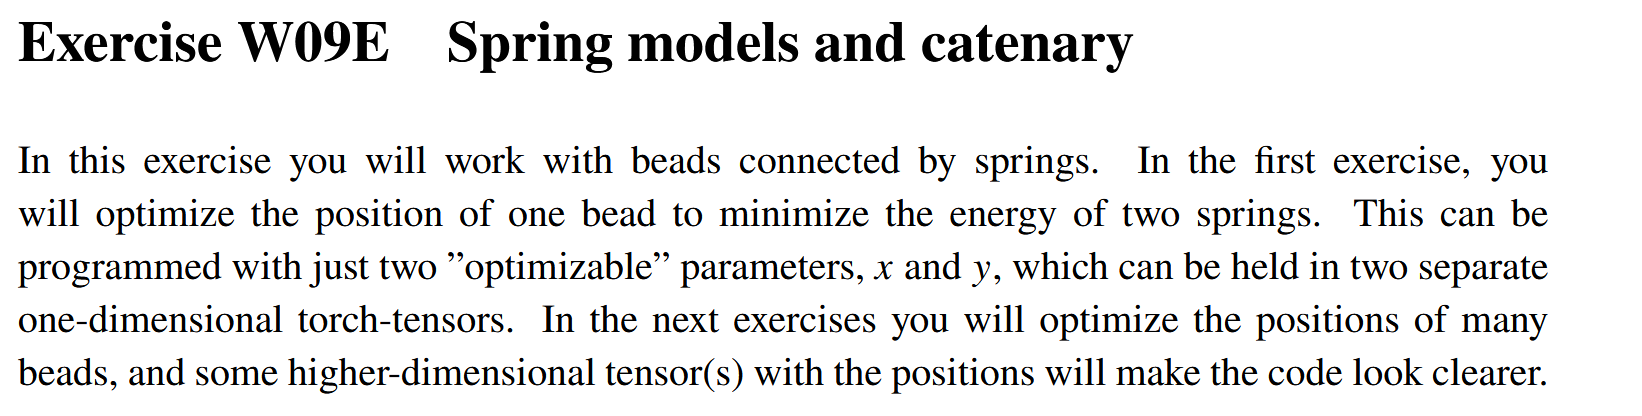
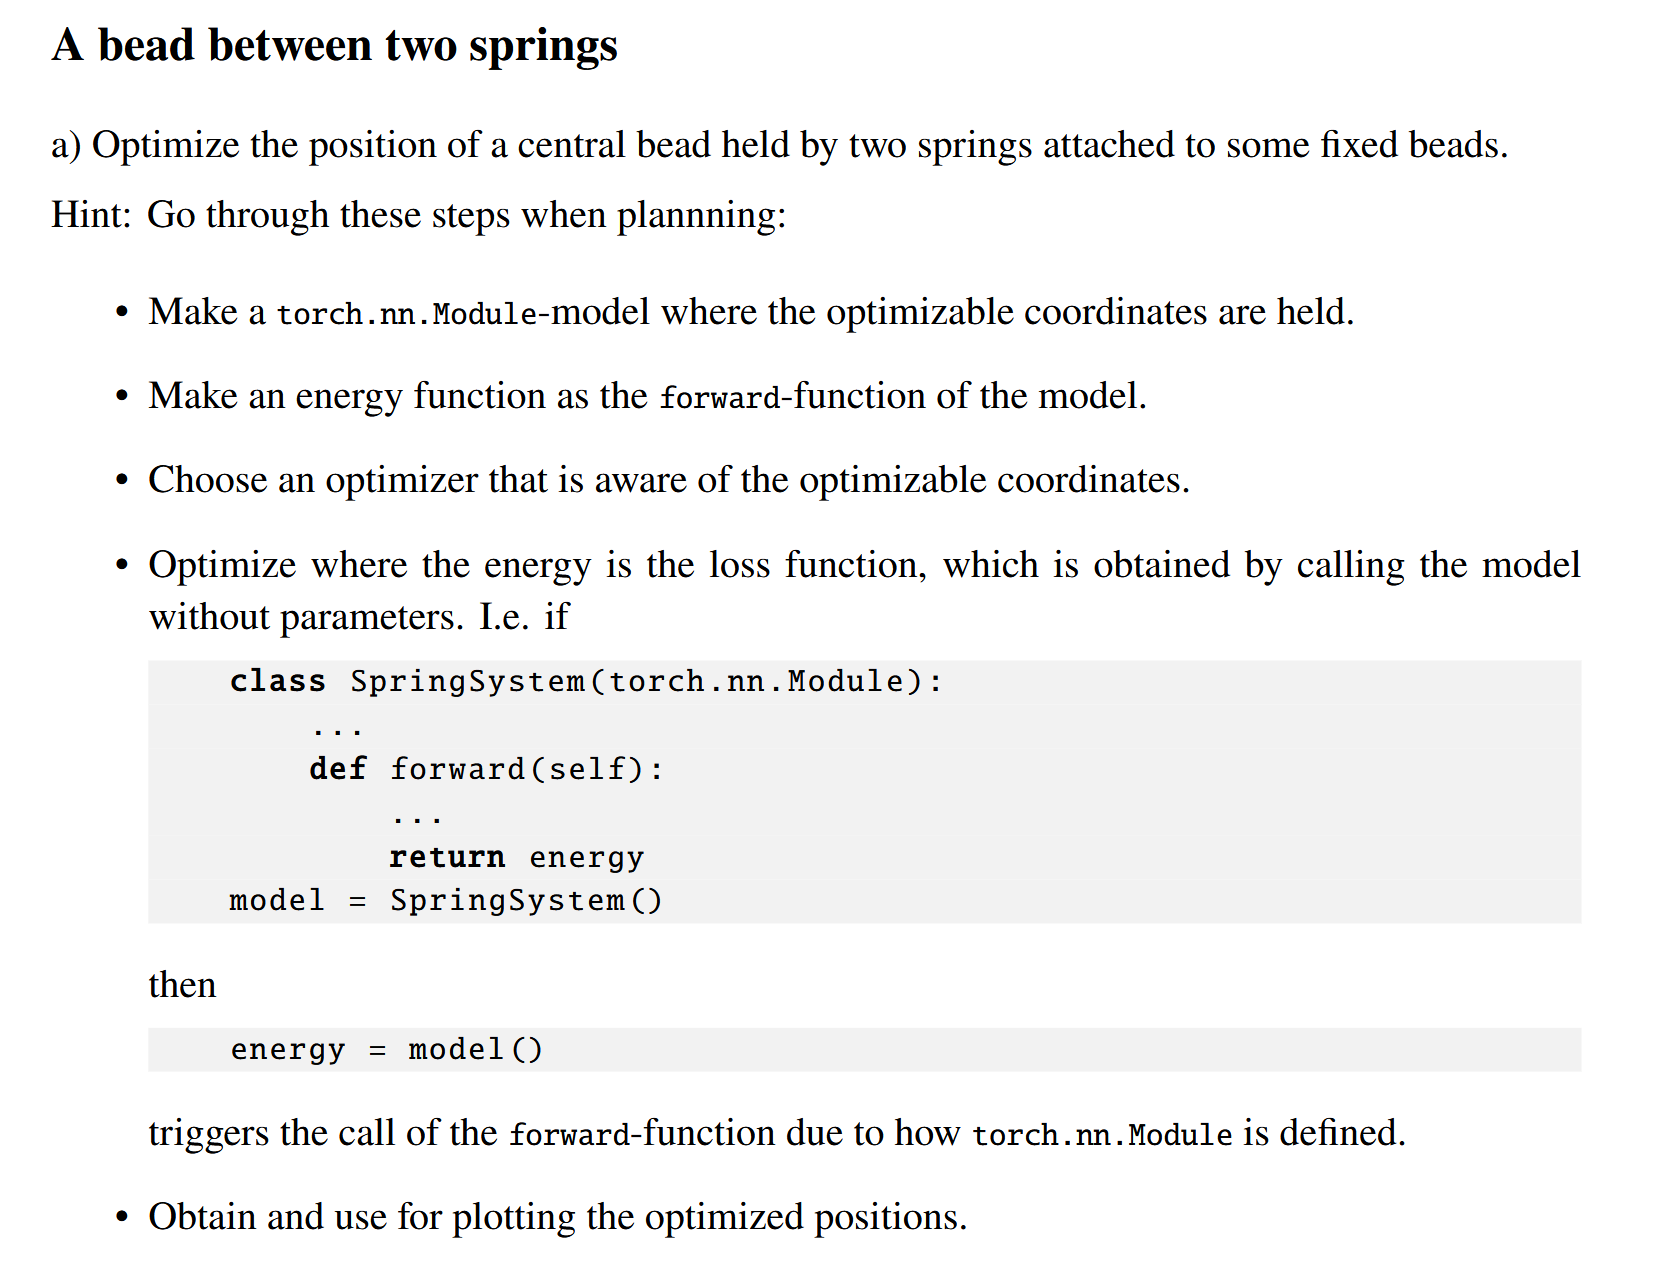

Final optimized central bead position: (2.013, 0.740)


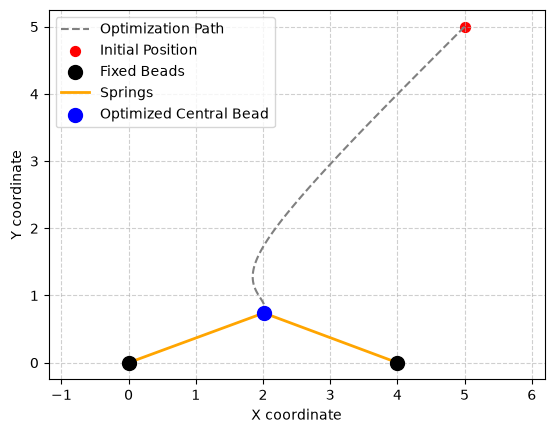

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

class SpringSystem(nn.Module):
    def __init__(self, *args, free=[0.0, 0.0], fixed=[], k=1.0, L0=2.0, **kwargs):
        super().__init__(*args, **kwargs)
        # Optimizable bead
        self.pos = nn.Parameter(torch.tensor(free, dtype=torch.float32))

        # Fixed beads
        self.fixed = torch.tensor(fixed, dtype=torch.float32)

        # Spring Constanst
        self.k = k
        self.l = L0

        self.history = None

    def forward(self):
        # Get pairwise distances 
        distances = torch.norm(self.pos - self.fixed, dim=1)

        energy = 0.5 * self.k * (distances - self.l)**2

        return torch.sum(energy)

    def optimize(self, epochs=100, lr=0.1):
        optimizer = optim.Adam(self.parameters(), lr=0.1)
        self.history = [self.pos.detach().numpy().copy()]

        epochs = 100
        for epoch in range(epochs):
            optimizer.zero_grad()
            
            energy = self() 
            energy.backward()
            optimizer.step()
            
            self.history.append(self.pos.detach().numpy().copy())

        return self.pos.detach().numpy()

    def plot(self, ax):
        if not self.history:
            print("Please run .optimize() before plotting.")
            return

        final_pos = self.pos.detach().numpy()
        history_arr = np.array(self.history)
        fixed_pts = self.fixed.numpy()

        # Plot the optimization trajectory and starting point
        ax.plot(history_arr[:, 0], history_arr[:, 1], color='gray', linestyle='--', label='Optimization Path')
        ax.scatter(history_arr[0, 0], history_arr[0, 1], color='red', s=50, label='Initial Position')

        # Plot all fixed beads and their connecting springs
        for i, fp in enumerate(fixed_pts):
            label = 'Fixed Beads' if i == 0 else ""
            spring_label = 'Springs' if i == 0 else ""
            plt.scatter(fp[0], fp[1], color='black', s=100, label=label, zorder=5)
            plt.plot([fp[0], final_pos[0]], [fp[1], final_pos[1]], color='orange', linewidth=2, label=spring_label)

        # Plot the final optimized bead
        ax.scatter(*final_pos, color='blue', s=100, label='Optimized Central Bead', zorder=5)

        ax.set(xlabel="X coordinate", 
               ylabel="Y coordinate")
        ax.axis('equal')
        ax.legend()
        ax.grid(True, linestyle='--', alpha=0.6)



initial = [5.0, 5.0]
anchor_points = [[0.0, 0.0], [4.0, 0.0]] 

model = SpringSystem(free=initial, fixed=anchor_points)

final_pos = model.optimize()

fig, ax = plt.subplots()
model.plot(ax)

print(f"Final optimized central bead position: ({final_pos[0]:.3f}, {final_pos[1]:.3f})")


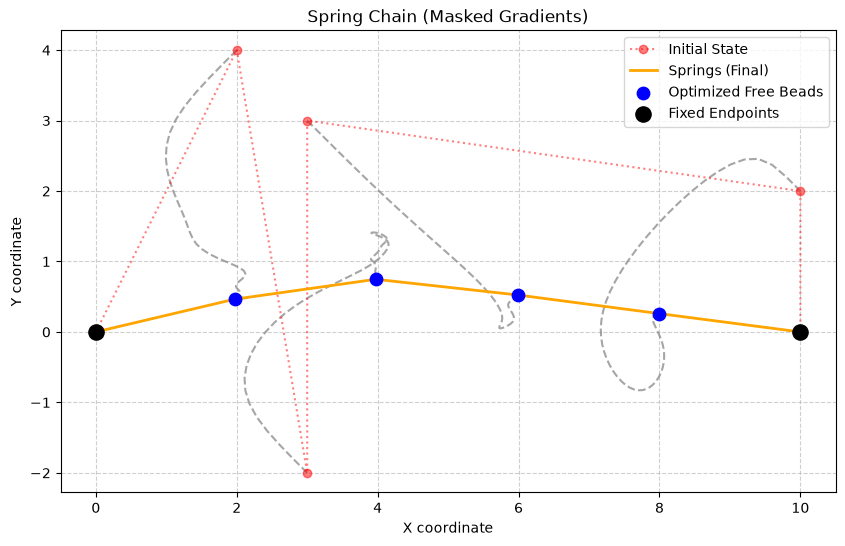

In [9]:
class SpringChainMasked(nn.Module):
    def __init__(self, *args, beads, k=1.0, L0=2.0, **kwargs):
        super().__init__(*args, **kwargs)
        
        # Keep the positions of all beads in one single torch tensor
        self.beads = nn.Parameter(torch.tensor(beads, dtype=torch.float32))

        # Spring Constanst
        self.k = k
        self.l = L0

        self.history = None
        

    def forward(self):
        # pairwise distance
        distances = torch.norm(self.beads[1:] - self.beads[:-1], dim=1)
        energies = 0.5 * self.k * (distances - self.l)**2
        return torch.sum(energies)

    def optimize(self, epochs=100, lr=0.1):
        optimizer = optim.Adam(self.parameters(), lr=lr)
        self.history = [self.beads.detach().numpy().copy()]
        
        for _ in range(epochs):
            optimizer.zero_grad()
            
            energy = self() 
            energy.backward()
            
            # zero out gradients for static parameters
            with torch.no_grad():
                self.beads.grad[0].zero_()
                self.beads.grad[-1].zero_()
                
            optimizer.step() 
            
            self.history.append(self.beads.detach().numpy().copy())
            
        return self.beads.detach().numpy()
    
    def plot(self, title="Spring Chain (Masked Gradients)"):
        if not self.history:
            print("Please run .optimize() before plotting.")
            return
            
        history_arr = np.array(self.history) # Shape: (epochs, total_beads, 2)
        final_chain = history_arr[-1]
        
        plt.figure(figsize=(10, 6))

        # Plot trajectories for the free beads (ignoring index 0 and -1)
        num_beads = history_arr.shape[1]
        for b in range(1, num_beads - 1):
            plt.plot(history_arr[:, b, 0], history_arr[:, b, 1], color='gray', linestyle='--', alpha=0.7)
            
        # Plot the initial state of the chain (Red)
        initial_chain = history_arr[0]
        plt.plot(initial_chain[:, 0], initial_chain[:, 1], color='red', linestyle=':', marker='o', label='Initial State', alpha=0.5)

        # Plot the final optimized state of the chain
        plt.plot(final_chain[:, 0], final_chain[:, 1], color='orange', linewidth=2, label='Springs (Final)')
        plt.scatter(final_chain[1:-1, 0], final_chain[1:-1, 1], color='blue', s=80, label='Optimized Free Beads', zorder=5)

        # Plot the fixed endpoints
        plt.scatter(final_chain[0, 0], final_chain[0, 1], color='black', s=120, label='Fixed Endpoints', zorder=5)
        plt.scatter(final_chain[-1, 0], final_chain[-1, 1], color='black', s=120, zorder=5)

        plt.title(title)
        plt.xlabel("X coordinate")
        plt.ylabel("Y coordinate")
        plt.axis('equal')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.show()

# First and last are fixed 
beads = [[0.0, 0.0], [2.0, 4.0], [3.0, -2.0], [3.0, 3.0], [10.0, 2.0], [10.0, 0.0]]

model = SpringChainMasked(beads=beads)
model.optimize(epochs=200, lr=0.2)
model.plot()


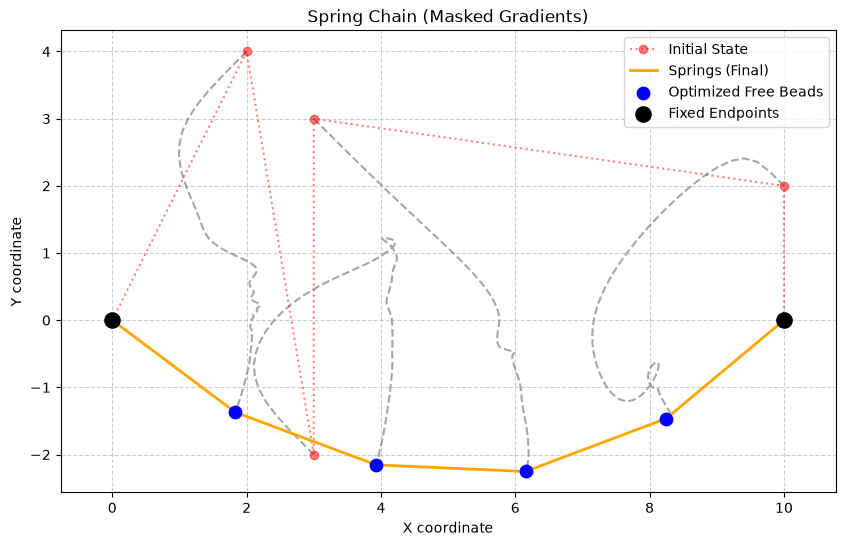

In [14]:
class GravitySpringSystem(SpringChainMasked):
    def __init__(self, *args, mass=1.0, **kwargs):
        super().__init__(*args, **kwargs)
        self.m = mass
    def forward(self):
        spring_energy = super().forward()
        # E_g = m*g*y
        gravitational_energy = torch.sum(self.beads[:, 1] * self.m * 9.82) 
        return spring_energy + gravitational_energy

# First and last are fixed 
beads = [[0.0, 0.0], [2.0, 4.0], [3.0, -2.0], [3.0, 3.0], [10.0, 2.0], [10.0, 0.0]]

model = GravitySpringSystem(beads=beads, mass=0.01)
model.optimize(epochs=200, lr=0.2)
model.plot()